# **Prediksi Karakteristik Penguin Menggunakan Model KMeans**

## **1. Bussines Understanding**

Sebuah pusat konservasi margasatwa dan peneliti biologi kelautan ingin membangun sistem
kecerdasan buatan berbasis Unsupervised Machine Learning untuk mengelompokkan
karakteristik fisik populasi penguin secara otomatis ke dalam beberapa klaster kelompok
morfologi tanpa perlu melakukan identifikasi manual secara terus-menerus di lapangan.

### **1.1 Latar Belakang**

Sebuah perusahaan konservasi margasatwa dan peneliti ingin membanugn sistem AI untuk mengelompokkan karakteristik penguin secara otomatis.

### **1.2 Tujuan**

Membangun sistem AI untuk memprediksi karakteristik penguin secara otomatis berdasarkan karakteristik fisik populasi penguin

### **1.3 Masalah**

Dalam proses penelitian, tim peniliti selalu kelapangan untuk mencari hasil penelitan dan tidak efisien baik waktu dan biaya


### **1.4 Solusi**

Solusi adalah dengan membangun sistem AI dengan menggunakan KMeans untuk memprediksi karakteristik penguin secara otomatis

### **1.5 Deskripsi tabel**

`Fitur Input (X): Kolom atribut fisik dan anatomi tubuh penguin, yang meliputi:`
-  culmen_length_mm: Panjang paruh penguin (culmen length) (satuan:
milimeter).
-  culmen_depth_mm: Kedalaman paruh penguin (culmen depth) (satuan:
milimeter).
-  flipper_length_mm: Panjang sirip penguin (flipper length) (satuan: milimeter).
-  body_mass_g: Berat badan penguin (satuan: gram).
-  sex: Jenis kelamin penguin (MALE / FEMALE).


`Target Label (Y): Tidak ada label target (karena menggunakan pembelajaran tanpa
pengawasan / unsupervised learning), di mana algoritma bertugas menemukan
kelompok klaster secara mandiri.`

## **2. Data Preparation**


In [376]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import tkinter as tk

In [377]:
# df = pd.read_csv('penguins.csv')
df = pd.read_csv('../dataset/penguins.csv')
df.head(10)

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE
5,39.3,20.6,190.0,3650.0,MALE
6,38.9,17.8,181.0,3625.0,FEMALE
7,39.2,19.6,195.0,4675.0,MALE
8,34.1,18.1,193.0,3475.0,NaN
9,42.0,20.2,5000.0,4250.0,MALE


In [378]:
df.info()
df.describe()
df.size

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   342 non-null    float64
 1   culmen_depth_mm    342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   sex                335 non-null    str    
dtypes: float64(4), str(1)
memory usage: 13.6 KB


1720

Terlihat dari dataset ini terdapat 344 baris data dan 5 kolom, dengan tipe data float dan string. Kemudian dataset ini memiliki frame data yaitu 1720. 

In [379]:
df.isnull().sum()

culmen_length_mm     2
culmen_depth_mm      2
flipper_length_mm    2
body_mass_g          2
sex                  9
dtype: int64

Terlihat pada dataset ini terdapat 17 missing value.

In [380]:
df.duplicated().sum()


np.int64(1)

Terlihat pada dataset ini terdapat 1 duplicate value.

## **3. Exploratory Data Analysis**

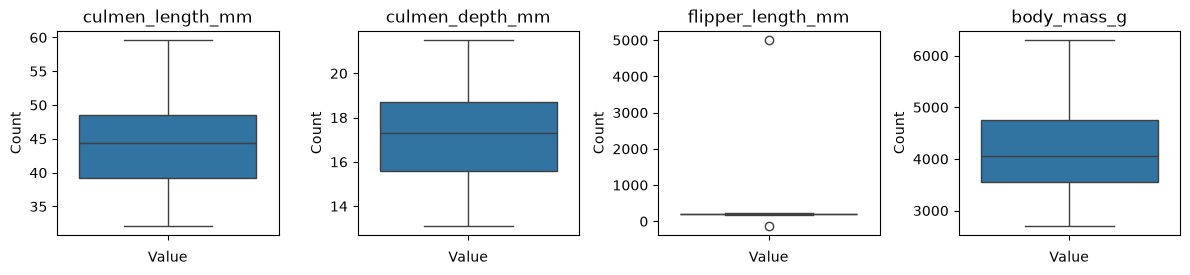

In [381]:
cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(12, 10))

for i, cols in enumerate(cols, start=1):
    plt.subplot(4, 4, i)
    sns.boxplot(df[cols])
    plt.title(cols)
    plt.xlabel('Value')
    plt.ylabel('Count')

plt.tight_layout(h_pad=1.0, w_pad=1.0)
plt.show()

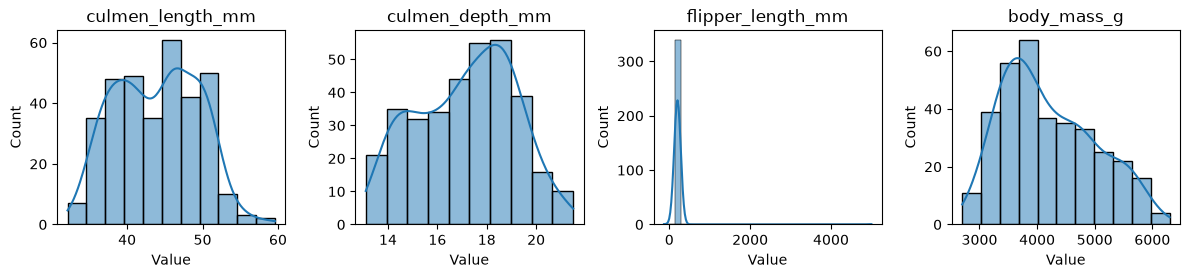

In [382]:
cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(12, 10))

for i, cols in enumerate(cols, start=1):
    plt.subplot(4, 4, i)
    sns.histplot(df[cols], kde=True)
    plt.title(cols)
    plt.xlabel('Value')
    plt.ylabel('Count')

plt.tight_layout(h_pad=1.0, w_pad=1.0)
plt.show()

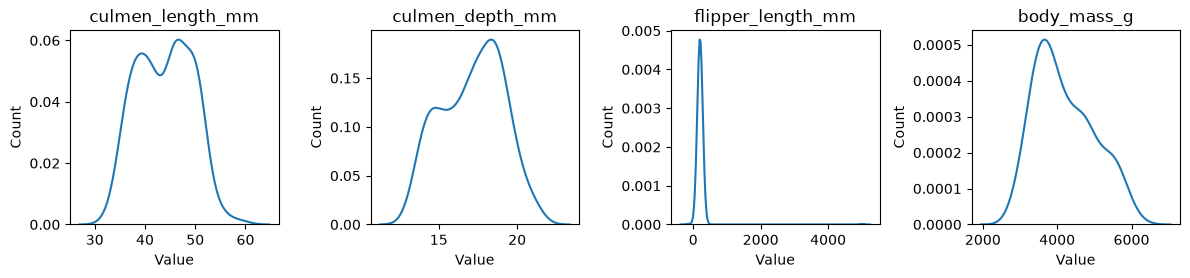

In [383]:
cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(12, 10))

for i, cols in enumerate(cols, start=1):
    plt.subplot(4, 4, i)
    sns.kdeplot(df[cols])
    plt.title(cols)
    plt.xlabel('Value')
    plt.ylabel('Count')

plt.tight_layout(h_pad=1.0, w_pad=1.0)
plt.show()

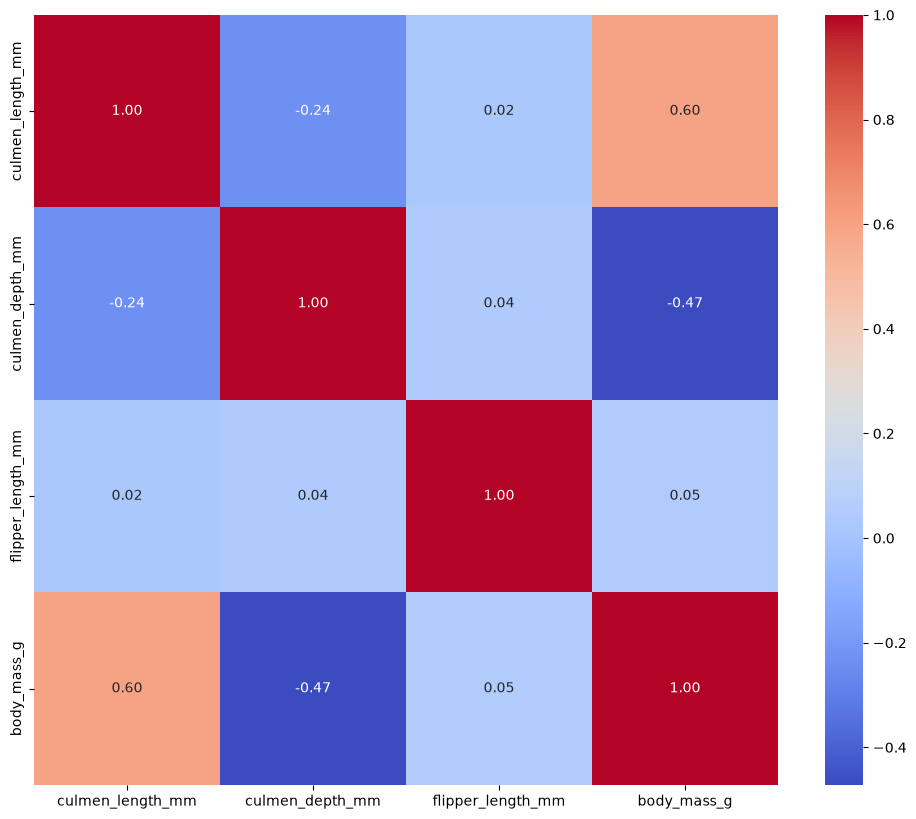

In [384]:
df_corr = df.select_dtypes(include=['number'])

plt.figure(figsize=(12, 10))

sns.heatmap(df_corr.corr(), annot=True, cmap='coolwarm', fmt=".2f")   
plt.show()

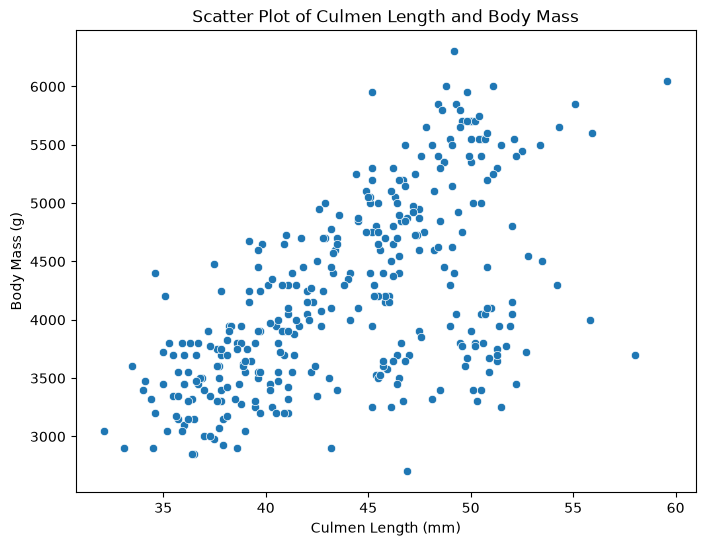

In [385]:
plt.figure(figsize=(8, 6))

sns.scatterplot(x='culmen_length_mm', y='body_mass_g', data=df)
plt.title('Scatter Plot of Culmen Length and Body Mass')
plt.xlabel('Culmen Length (mm)')
plt.ylabel('Body Mass (g)')
plt.show()
plt.close()

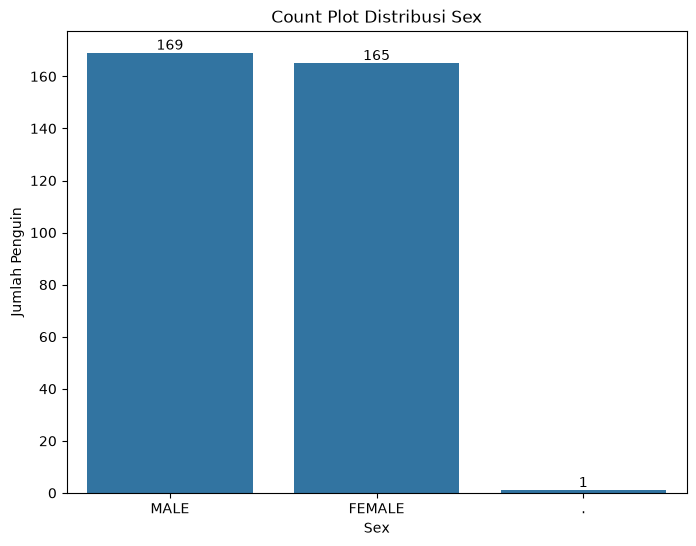

sex               .  FEMALE  MALE
rentang_mass                     
(2696.4, 3420.0]  0      52     4
(3420.0, 4140.0]  0      55    66
(4140.0, 4860.0]  0      42    39
(4860.0, 5580.0]  1      16    38
(5580.0, 6300.0]  0       0    22


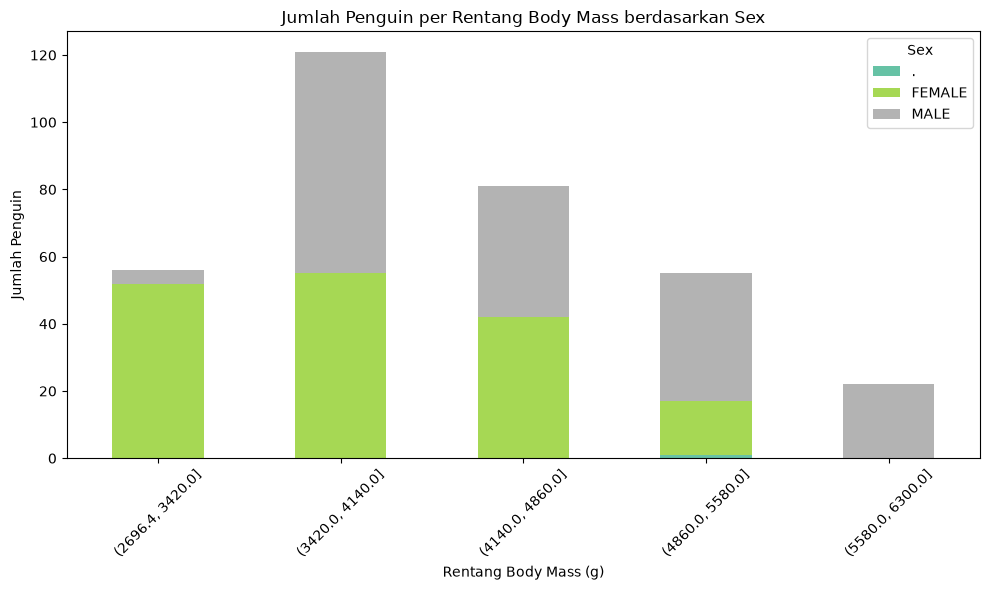

In [386]:
# --- Count Plot: jumlah penguin per kategori sex ---
plt.figure(figsize=(8, 6))
ax = sns.countplot(x='sex', data=df, order=df['sex'].value_counts().index)
ax.bar_label(ax.containers[0])
plt.title('Count Plot Distribusi Sex')
plt.xlabel('Sex')
plt.ylabel('Jumlah Penguin')
plt.show()
plt.close()

# --- Stacked Bar: jumlah penguin per rentang body mass ditumpuk berdasarkan sex ---
df_eda = df.dropna(subset=['sex']).copy()
df_eda['rentang_mass'] = pd.cut(df_eda['body_mass_g'], bins=5)

tabel = pd.crosstab(df_eda['rentang_mass'], df_eda['sex'])
print(tabel)

tabel.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='Set2')
plt.title('Jumlah Penguin per Rentang Body Mass berdasarkan Sex')
plt.xlabel('Rentang Body Mass (g)')
plt.ylabel('Jumlah Penguin')
plt.legend(title='Sex')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
plt.close()

Dari count plot terlihat sex diisi 169 MALE dan 165 FEMALE, namun muncul satu kategori tambahan berupa `'.'`. Nilai `'.'` ini bukan jenis kelamin yang sah, melainkan hidden missing value yang nantinya ditangani pada tahap Data Preprocessing.

Dari stacked bar chart terlihat bahwa penguin FEMALE mayoritas berada pada rentang body mass rendah (2696-3420 g), sedangkan MALE mendominasi rentang tinggi (4860-6300 g). Ini menandakan body mass berhubungan dengan sex, sehingga pengelompokan KMeans berpotensi memisahkan penguin berdasarkan ukuran tubuh.

## **4. Data Preprocessing**

In [387]:
df.dropna(inplace=True)

In [388]:
df.isnull().sum()

culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

In [389]:
# Menghapus data duplikat
df = df.drop_duplicates()

# Reset index setelah penghapusan
df = df.reset_index(drop=True)

In [390]:
df.duplicated().sum()

np.int64(0)

In [391]:
df['sex'] = df['sex'].map({'MALE': 0, 'FEMALE': 1})


In [392]:
cols = df.select_dtypes(include=['number']).columns

Q1 =  df[cols].quantile(0.25)
Q3 =  df[cols].quantile(0.75)

IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier = ((df[cols] < batas_bawah)| (df[cols] > batas_atas))
outlier_sebelum = outlier.sum()

df = df.loc[~outlier.any(axis=1)].reset_index(drop=True)

outlier_sesudah = ((df[cols] < batas_bawah)| (df[cols] > batas_atas)).sum()

print(outlier_sebelum)
print('===========================')
print(outlier_sesudah)

culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    2
body_mass_g          0
sex                  0
dtype: int64
culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64


## **7. GUI**

In [393]:
df.head(10)

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,0.0
1,39.5,17.4,186.0,3800.0,1.0
2,40.3,18.0,195.0,3250.0,1.0
3,36.7,19.3,193.0,3450.0,1.0
4,39.3,20.6,190.0,3650.0,0.0
5,38.9,17.8,181.0,3625.0,1.0
6,39.2,19.6,195.0,4675.0,0.0
7,41.1,17.6,182.0,3200.0,1.0
8,38.6,21.2,191.0,3800.0,0.0
9,36.6,17.8,185.0,3700.0,1.0


In [394]:
KOLOM_KATEGORIK = X.select_dtypes(exclude='number').columns.tolist()

X_train_enc = X_train.copy()
X_test_enc  = X_test.copy()

for col in KOLOM_KATEGORIK:
    uniques = pd.unique(X_train_enc[col].fillna('Unknown')) # urutan kategori dari train

    for data in (X_train_enc, X_test_enc):
        data[col] = pd.Categorical(
            data[col].fillna('Unknown'),
            categories=uniques # dikunci ke train
        ).codes  # kategori baru -> -1

NameError: name 'X' is not defined